In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.signal import savgol_filter
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy import sparse
from scipy.sparse.linalg import spsolve



normiertes Ramanspektrum für Referenzprobe - CNT - auf Steg - Rohdaten

[-261.97517861 -260.94645795 -259.91773729 ... 4348.7185375  4349.63339699
 4350.54825647]
[0.01159113 0.01322466 0.01323335 ... 0.00356684 0.00647765 0.00178125]


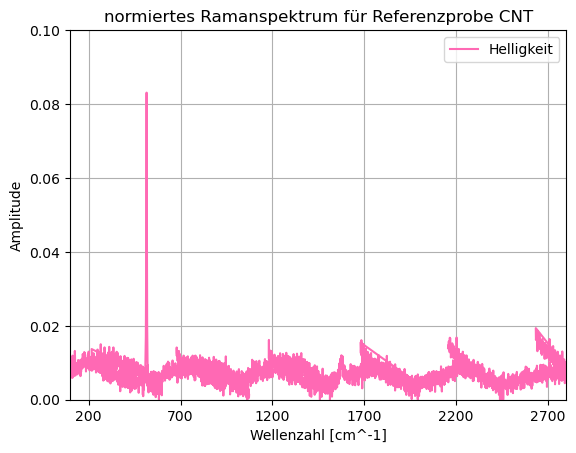

In [3]:
# Rohdaten einlesen

messdaten_auf_pet = np.genfromtxt(
    'Referenzprobe CNT - auf Pet.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

wellenzahl_cm = messdaten_auf_pet[:,0]
amplitude = messdaten_auf_pet[:,1]

# Überprüfung des Einlesens und Speicherns
print(wellenzahl_cm)
print(amplitude)

# Plot nur im wichtigen Bereich (ohne Rayleight und Ende Spektrum)
plt.plot(wellenzahl_cm, amplitude, color='hotpink', label='Helligkeit')
plt.xticks(np.arange(-300, 5000, 500))  
plt.xlim(100,2800)
plt.ylim(0,0.1)
plt.title('normiertes Ramanspektrum für Referenzprobe CNT')
plt.xlabel('Wellenzahl [cm^-1]')
plt.ylabel('Amplitude') 
plt.legend()
plt.grid(True)
plt.show()

normiertes Ramanspektrum für Referenzprobe - CNT - auf Pet - RBM

C:\Users\nelln\AppData\Local\Temp\ipykernel_19504\3537544444.py:26: SparseEfficiencyWarning: spsolve requires A be CSC or CSR matrix format
  z = spsolve(Z, w * y)


Hauptpeak gezielt gefunden bei: 171.12 cm⁻¹
Fit erfolgreich! Parameter: Amplitude=0.0047, Position=174.41 cm⁻¹, Gamma=15.00
Berechnete Halbwertsbreite (FWHM):
RBM Peak: FWHM = 30.00 cm⁻¹  (gamma = 15.00)


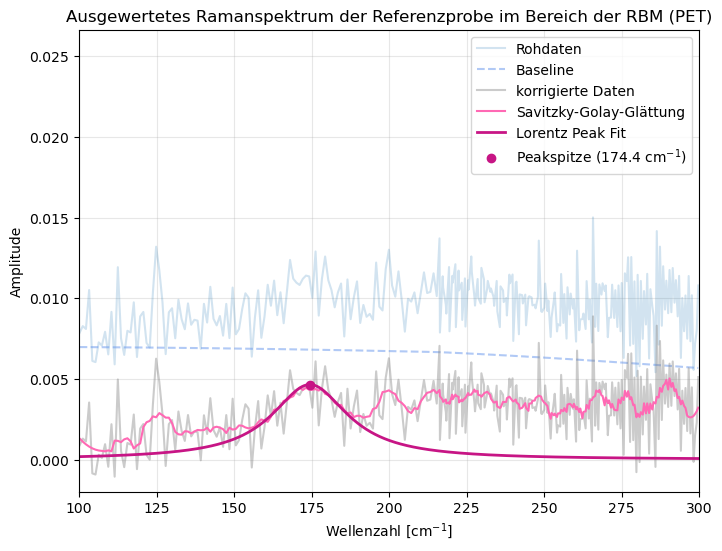

In [ ]:
# Rohdaten einlesen und sortieren
messdaten_auf_pet = np.genfromtxt(
    'Referenzprobe CNT - auf Pet.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

wellenzahl_cm = messdaten_auf_pet[:,0]
amplitude = messdaten_auf_pet[:,1]

idx = np.argsort(wellenzahl_cm)
wellenzahl_cm = wellenzahl_cm[idx]
amplitude = amplitude[idx]

# Baseline-Funktion (ALS)
def baseline_als(y, lam=1e6, p=0.01, niter=10):
    L = len(y)
    D = sparse.diags([1, -2, 1], [0, -1, -2], shape=(L, L))
    w = np.ones(L)

    for i in range(niter):
        W = sparse.diags(w, 0)
        Z = W + lam * D.dot(D.T)
        z = spsolve(Z, w * y)
        w = p * (y > z) + (1 - p) * (y < z)

    return z

# Baseline über das gesamte Spektrum mit starker Glättung (lam=1e8)
baseline_full = baseline_als(amplitude, lam=1e8, p=0.01)

# Beschränkung x-Achse auf das RBM-Fenster
mask = (wellenzahl_cm >= 100) & (wellenzahl_cm <= 300)

wellenzahl_cut = wellenzahl_cm[mask]
amplitude_cut = amplitude[mask]
baseline_cut = baseline_full[mask] 

# Korrektur der Rohdaten (Baseline-Abzug)
corrected_cut = amplitude_cut - baseline_cut

# Savitzky-Golay Glättung
window_length = 15  
polyorder = 2

if len(corrected_cut) < window_length:
    window_length = len(corrected_cut) if len(corrected_cut) % 2 != 0 else len(corrected_cut) - 1

smoothed_cut = savgol_filter(corrected_cut, window_length=window_length, polyorder=polyorder)

rbm_search_mask = (wellenzahl_cut >= 140) & (wellenzahl_cut <= 200)

peaks, _ = find_peaks(smoothed_cut, prominence=0.001)
# Filter nur die Peaks heraus, die im Suchfenster liegen
valid_peaks = [p for p in peaks if 140 <= wellenzahl_cut[p] <= 200]

if len(valid_peaks) < 1:
    # Fallback, falls kein lokales Maximum gefunden wird: Nimm das absolute Maximum im Fenster
    main_peak_idx = np.where(wellenzahl_cut >= 140)[0][0] + np.argmax(smoothed_cut[rbm_search_mask])
else:
    peak_heights = smoothed_cut[valid_peaks]
    main_peak_idx = valid_peaks[np.argmax(peak_heights)]

peak_center = wellenzahl_cut[main_peak_idx]
print(f"Hauptpeak gezielt gefunden bei: {peak_center:.2f} cm⁻¹")

# Lorentz-Fit für den einzelnen Peak
def lorentz(x, A, x0, gamma):
    return A * (gamma**2 / ((x - x0)**2 + gamma**2))

# Engerer Fit-Bereich um den echten Peak herum, damit das Rauschen den Fit nicht wegzieht
p_mask = (wellenzahl_cut >= peak_center - 20) & (wellenzahl_cut <= peak_center + 20)
x_fit, y_fit = wellenzahl_cut[p_mask], smoothed_cut[p_mask]

# Startwerte und Grenzen [Amplitude, Position, Gamma]
p0 = [smoothed_cut[main_peak_idx], peak_center, 6] 
lower_bounds = [0, peak_center - 5, 2]
upper_bounds = [smoothed_cut[main_peak_idx] * 2, peak_center + 5, 15]

try:
    params, _ = curve_fit(lorentz, x_fit, y_fit, p0=p0, bounds=(lower_bounds, upper_bounds), maxfev=5000)
    print(f"Fit erfolgreich! Parameter: Amplitude={params[0]:.4f}, Position={params[1]:.2f} cm⁻¹, Gamma={params[2]:.2f}")
    plot_fit = True
except Exception as e:
    print(f"WARNUNG: Lorentz-Fit fehlgeschlagen! Grund: {e}")
    params = [smoothed_cut[main_peak_idx], peak_center, 6]
    plot_fit = False

# Speicherung Parameter für Gesamtspektrum später
params_rbm = np.array(params).copy()

# FWHM
if plot_fit:
    gamma_rbm = params[2]
    fwhm_rbm = 2 * gamma_rbm
    
    print("Berechnete Halbwertsbreite (FWHM):")
    print(f"RBM Peak: FWHM = {fwhm_rbm:.2f} cm⁻¹  (gamma = {gamma_rbm:.2f})")

# Plot
plt.figure(figsize=(8, 6))
plt.xlim(100, 300)
# Skalierung der Y-Achse angepasst an die echte Peak-Region
plt.ylim(-0.002, np.max(corrected_cut) * 3)

plt.plot(wellenzahl_cut, amplitude_cut, 'tab:blue', alpha=0.2, label="Rohdaten")
plt.plot(wellenzahl_cut, baseline_cut, linestyle = '--', color = 'cornflowerblue', alpha=0.5, label="Baseline")
plt.plot(wellenzahl_cut, corrected_cut, 'tab:gray', alpha=0.4, label="korrigierte Daten")
plt.plot(wellenzahl_cut, smoothed_cut, color = 'hotpink', linewidth=1.5, label="Savitzky-Golay-Glättung")

if plot_fit:
    x_plot = np.linspace(100, 300, 1000)
    plt.plot(x_plot, lorentz(x_plot, *params), color = 'mediumvioletred', label='Lorentz Peak Fit', linewidth=2)
    plt.plot(params[1], params[0], color = 'mediumvioletred', marker = 'o', linestyle = 'none', label=f'Peakspitze ({params[1]:.1f} cm$^{{-1}}$)')

plt.title('Ausgewertetes Ramanspektrum der Referenzprobe im Bereich der RBM (PET)')
plt.xlabel('Wellenzahl [cm$^{-1}$]')
plt.ylabel('Amplitude') 
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.show()

Echtes physikalisches Maximum gefunden bei: 515.39 cm⁻¹
Fit erfolgreich! Parameter: Amplitude=0.0791, Position=515.15 cm⁻¹, Gamma=0.78
Berechnete Halbwertsbreite (FWHM):
Si-TO Substratpeak: FWHM = 1.56 cm⁻¹  (gamma = 0.78)


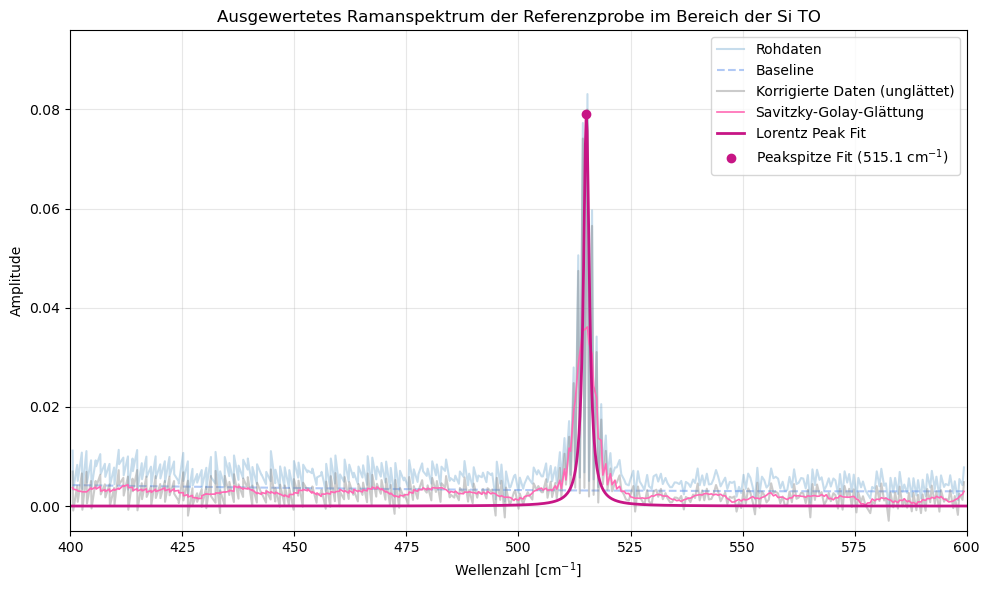

In [4]:
# Rohdaten einlesen und sortieren
messdaten_auf_pet = np.genfromtxt(
    'Referenzprobe CNT - auf Pet.txt',
    delimiter='\t',
    converters={
        0: lambda s: float(s.decode('utf-8').replace(',', '.')),
        1: lambda s: float(s.decode('utf-8').replace(',', '.'))
    }
)

wellenzahl_cm = messdaten_auf_pet[:,0]
amplitude = messdaten_auf_pet[:,1]

idx = np.argsort(wellenzahl_cm)
wellenzahl_cm = wellenzahl_cm[idx]
amplitude = amplitude[idx]

# Baseline-Funktion (ALS)
def baseline_als(y, lam=1e8, p=0.01, niter=10):
    L = len(y)
    D = sparse.diags([1, -2, 1], [0, -1, -2], shape=(L, L))
    w = np.ones(L)

    for i in range(niter):
        W = sparse.diags(w, 0)
        Z = W + lam * D.dot(D.T)
        z = spsolve(Z, w * y)
        w = p * (y > z) + (1 - p) * (y < z)

    return z

# Lorentz-Funktion
def lorentz(x, A, x0, gamma):
    return A * (gamma**2 / ((x - x0)**2 + gamma**2))

# Baseline über das gesamte Spektrum berechnen
baseline_full = baseline_als(amplitude, lam=1e8, p=0.01)

# Beschränkung auf das Si-TO-Fenster
mask = (wellenzahl_cm >= 400) & (wellenzahl_cm <= 600)

wellenzahl_cut = wellenzahl_cm[mask]
amplitude_cut = amplitude[mask]
baseline_cut = baseline_full[mask] 

# Korrektur der Rohdaten (Baseline-Abzug)
corrected_cut = amplitude_cut - baseline_cut

# Savitzky-Golay Glättung
window_length = 15  
polyorder = 2

if len(corrected_cut) < window_length:
    window_length = len(corrected_cut) if len(corrected_cut) % 2 != 0 else len(corrected_cut) - 1

smoothed_cut = savgol_filter(corrected_cut, window_length=window_length, polyorder=polyorder)

# Peak-Finding auf den geglätteten Daten
peaks, _ = find_peaks(smoothed_cut, prominence=0.002)

if len(peaks) < 1:
    raise ValueError("Kein Peak im Bereich gefunden!")

# Grobes Zentrum bestimmen
main_peak_idx = peaks[np.argmax(smoothed_cut[peaks])]
peak_center_grob = wellenzahl_cut[main_peak_idx]

# Suche nach dem ungeglätteten Maximum in direkter Umgebung
search_area = (wellenzahl_cut >= peak_center_grob - 5) & (wellenzahl_cut <= peak_center_grob + 5)
real_max_amp = np.max(corrected_cut[search_area])
real_max_welle = wellenzahl_cut[search_area][np.argmax(corrected_cut[search_area])]

print(f"Echtes physikalisches Maximum gefunden bei: {real_max_welle:.2f} cm⁻¹")

# Fit-Maske eng um das wahre Maximum legen (+- 15 cm^-1)
fit_mask = (wellenzahl_cut >= real_max_welle - 15) & (wellenzahl_cut <= real_max_welle + 15)

x_fit = wellenzahl_cut[fit_mask]
y_fit = corrected_cut[fit_mask]  # Wir fitten die ungestauchten korrigierten Daten

# Startwerte: [Amplitude, Position, Halbwertsbreite]
p0 = [real_max_amp, real_max_welle, 4]

# Grenzen definieren: Die Amplitude DARF mathematisch nicht unter 99% des Peaks fallen
lower_bounds = [real_max_amp * 0.99, real_max_welle - 2, 0.5]
upper_bounds = [real_max_amp * 1.05, real_max_welle + 2, 12]

try:
    params, _ = curve_fit(
        lorentz, 
        x_fit, 
        y_fit, 
        p0=p0, 
        bounds=(lower_bounds, upper_bounds), 
        maxfev=10000
    )
    print(f"Fit erfolgreich! Parameter: Amplitude={params[0]:.4f}, Position={params[1]:.2f} cm⁻¹, Gamma={params[2]:.2f}")
    plot_fit = True
except Exception as e:
    print(f"WARNUNG: Mathematischer Fit blockiert ({e}). Nutze Fallback-Maximum.")
    params = np.array([real_max_amp, real_max_welle, 4.0])
    plot_fit = True

# Parameter für das Gesamtspektrum später
params_si_to = params.copy()

if plot_fit:
    gamma_si_to = params[2]
    fwhm_si_to = 2 * gamma_si_to
    
    print("Berechnete Halbwertsbreite (FWHM):")
    print(f"Si-TO Substratpeak: FWHM = {fwhm_si_to:.2f} cm⁻¹  (gamma = {gamma_si_to:.2f})")

# Plot
plt.figure(figsize=(10, 6))
plt.xlim(400, 600)
plt.ylim(-0.005, np.max(corrected_cut) * 1.2)

# Daten-Kurven
plt.plot(wellenzahl_cut, amplitude_cut, 'tab:blue', alpha=0.25, label="Rohdaten")
plt.plot(wellenzahl_cut, baseline_cut, linestyle='--', color='cornflowerblue', alpha=0.5, label="Baseline")
plt.plot(wellenzahl_cut, corrected_cut, 'tab:gray', alpha=0.4, label="Korrigierte Daten (unglättet)")
plt.plot(wellenzahl_cut, smoothed_cut, color='hotpink', linewidth=1.2, label="Savitzky-Golay-Glättung")

if plot_fit:
    x_plot = np.linspace(400, 600, 1000)
    plt.plot(x_plot, lorentz(x_plot, *params), color='mediumvioletred', label='Lorentz Peak Fit', linewidth=2)
    plt.plot(params[1], params[0], color='mediumvioletred', marker='o', linestyle='none', zorder=5,
             label=f'Peakspitze Fit ({params[1]:.1f} cm$^{{-1}}$)')

plt.title('Ausgewertetes Ramanspektrum der Referenzprobe im Bereich der Si TO')
plt.xlabel('Wellenzahl [cm$^{-1}$]')
plt.ylabel('Amplitude') 
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

C:\Users\nelln\AppData\Local\Temp\ipykernel_19504\3618995507.py:23: SparseEfficiencyWarning: spsolve requires A be CSC or CSR matrix format
  z = spsolve(Z, w * y)


-> Globaler 2-Peak-Fit erfolgreich!
GEFITТETE PEAKS (Zentrum | FWHM):
1200er-Modus: Zentrum = 1220.00 cm⁻¹ | FWHM = 160.00 cm⁻¹
G-Band:        Zentrum = 1579.30 cm⁻¹ | FWHM = 50.00 cm⁻¹


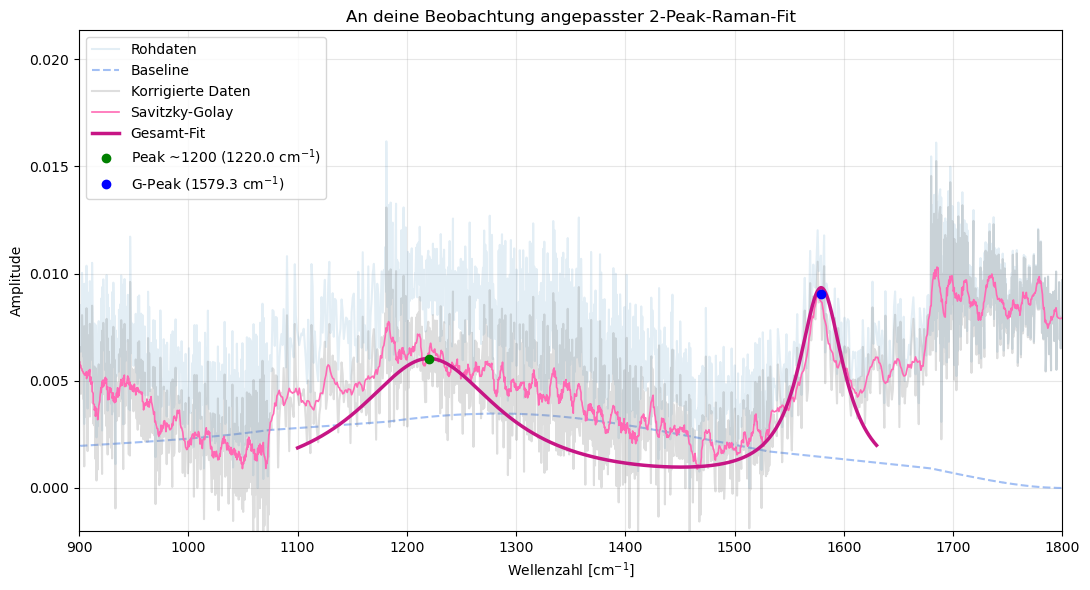

In [61]:
# Rohdaten einlesen und speichern
messdaten_auf_pet = np.genfromtxt('Referenzprobe CNT - auf Pet.txt', delimiter='\t', 
    converters={
        0: lambda s: float(s.replace(',', '.')),
        1: lambda s: float(s.replace(',', '.'))
    }
)

wellenzahl_cm = messdaten_auf_pet[:,0]
amplitude = messdaten_auf_pet[:,1]

idx = np.argsort(wellenzahl_cm)
wellenzahl_cm = wellenzahl_cm[idx]
amplitude = amplitude[idx]

def baseline_als(y, lam=1e8, p=0.01, niter=10):
    L = len(y)
    D = sparse.diags([1, -2, 1], [0, -1, -2], shape=(L, L))
    w = np.ones(L)
    for i in range(niter):
        W = sparse.diags(w, 0)
        Z = W + lam * D.dot(D.T)
        z = spsolve(Z, w * y)
        w = p * (y > z) + (1 - p) * (y < z)
    return z

def lorentz(x, A, x0, gamma):
    return A * (gamma**2 / ((x - x0)**2 + gamma**2))

# Zwei Peaks: 1200er-Struktur und G-Band
def raman_2peak_model(x, A_1200, x0_1200, g_1200, A_G, x0_G, g_G):
    return (lorentz(x, A_1200, x0_1200, g_1200) + 
            lorentz(x, A_G, x0_G, g_G))

# Daten ausschneiden
mask = (wellenzahl_cm >= 900) & (wellenzahl_cm <= 1800)
wellenzahl_cut = wellenzahl_cm[mask]
amplitude_cut = amplitude[mask]

baseline_cut = baseline_als(amplitude_cut, lam=1e8, p=0.01) 
corrected_cut = amplitude_cut - baseline_cut

smoothed_cut = savgol_filter(corrected_cut, window_length=21, polyorder=2)

# Fit-Bereich (schneidet den fehlerhaften Sprung ab 1630 cm⁻¹ ab)
fit_mask = (wellenzahl_cut >= 1100) & (wellenzahl_cut <= 1630)
x_fit = wellenzahl_cut[fit_mask]
y_fit = corrected_cut[fit_mask] 

# Startwerte [A, x0, gamma] für 2 Peaks:
p0 = [
    0.003, 1180, 40,  # Der Peak bei ~1180-1200 cm⁻¹
    0.006, 1580, 15   # Der scharfe Hauptpeak bei 1580 cm⁻¹
]

# Grenzen setzen, damit jeder Peak in seiner "Zone" bleibt
lower_bounds = [
    0, 1140, 15,  
    0, 1565, 5    
]
upper_bounds = [
    0.006, 1220, 80,  
    0.012, 1595, 25   
]

try:
    popt, _ = curve_fit(raman_2peak_model, x_fit, y_fit, p0=p0, bounds=(lower_bounds, upper_bounds), maxfev=20000)
    print("-> Globaler 2-Peak-Fit erfolgreich!")
    plot_fit = True
except Exception as e:
    print(f"-> FEHLER beim Fit: {e}")
    plot_fit = False

# Speichern Gesamtplot
if plot_fit:
    params_1200 = popt[0:3]  # Sichert Werte 0, 1, 2 (1200 cm⁻¹ Peak)
    params_g    = popt[3:6]  # Sichert Werte 3, 4, 5 (G-Band)
    
    # Berechne FWHM (Halbwertsbreiten)
    fwhm_1200 = 2 * params_1200[2]
    fwhm_g    = 2 * params_g[2]
    
    # Terminal-Ausgabe zur Kontrolle
    print("GEFITТETE PEAKS (Zentrum | FWHM):")
    print(f"1200er-Modus: Zentrum = {params_1200[1]:.2f} cm⁻¹ | FWHM = {fwhm_1200:.2f} cm⁻¹")
    print(f"G-Band:        Zentrum = {params_g[1]:.2f} cm⁻¹ | FWHM = {fwhm_g:.2f} cm⁻¹")
    
else:
    params_1200 = params_g = None

# Plot
plt.figure(figsize=(11, 6))
plt.xlim(900, 1800)
plt.ylim(-0.002, np.max(corrected_cut) * 1.4)

plt.plot(wellenzahl_cut, amplitude_cut, 'tab:blue', alpha=0.12, label="Rohdaten")
plt.plot(wellenzahl_cut, baseline_cut, linestyle='--', color='cornflowerblue', alpha=0.6, label="Baseline")
plt.plot(wellenzahl_cut, corrected_cut, 'tab:gray', alpha=0.25, label="Korrigierte Daten")
plt.plot(wellenzahl_cut, smoothed_cut, color='hotpink', linewidth=1.2, label="Savitzky-Golay")

if plot_fit:
    x_plot = np.linspace(1100, 1630, 1000)
    
    # Gesamt-Fit
    plt.plot(x_plot, raman_2peak_model(x_plot, *popt), color='mediumvioletred', linewidth=2.5, label='Gesamt-Fit')
    
    # Spitzen markieren
    plt.plot(params_1200[1], params_1200[0], 'go', zorder=5, label=f'Peak ~1200 ({params_1200[1]:.1f} cm$^{{-1}}$)')
    plt.plot(params_g[1], params_g[0], 'bo', zorder=5, label=f'G-Peak ({params_g[1]:.1f} cm$^{{-1}}$)')

plt.title('Angepasster 2-Peak-Raman-Fit')
plt.xlabel('Wellenzahl [cm$^{-1}$]')
plt.ylabel('Amplitude') 
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

C:\Users\nelln\AppData\Local\Temp\ipykernel_19504\3665940049.py:26: SparseEfficiencyWarning: spsolve requires A be CSC or CSR matrix format
  z = spsolve(Z, w * y)


Fit erfolgreich! Parameter: Amplitude=0.0052, Position=2577.73 cm⁻¹, Gamma=40.00
Berechnete Halbwertsbreite (FWHM):
Peak: FWHM = 80.00 cm⁻¹  (gamma = 40.00)


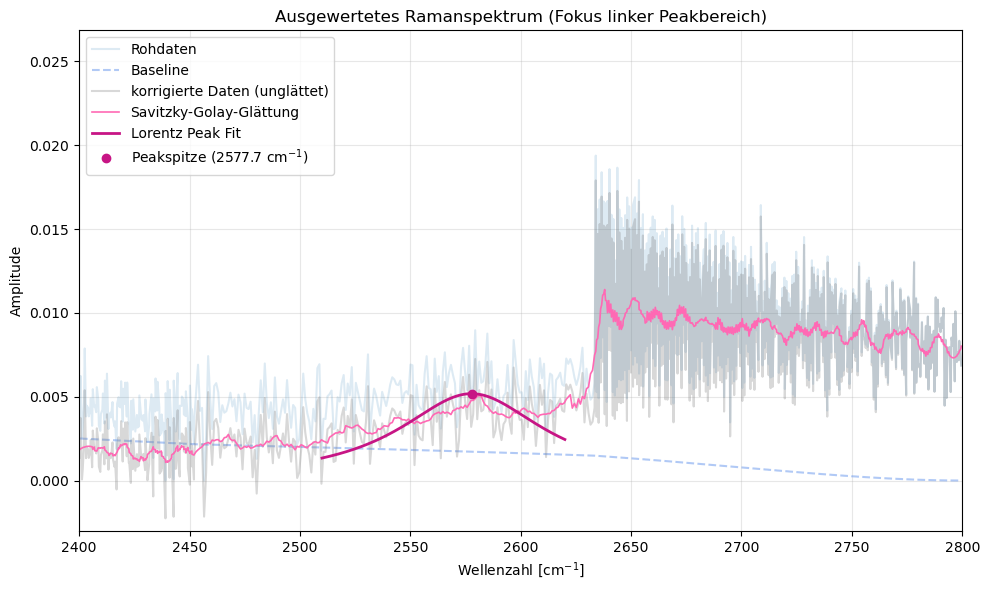

In [62]:

# Rohdaten einlesen und sortieren
messdaten_auf_pet = np.genfromtxt('Referenzprobe CNT - auf Pet.txt', delimiter='\t', 
    converters={
        0: lambda s: float(s.replace(',', '.')),
        1: lambda s: float(s.replace(',', '.'))
    }
)

wellenzahl_cm = messdaten_auf_pet[:,0]
amplitude = messdaten_auf_pet[:,1]

idx = np.argsort(wellenzahl_cm)
wellenzahl_cm = wellenzahl_cm[idx]
amplitude = amplitude[idx]

# Baseline (ALS)
def baseline_als(y, lam=1e6, p=0.01, niter=10):
    L = len(y)
    D = sparse.diags([1, -2, 1], [0, -1, -2], shape=(L, L))
    w = np.ones(L)

    for i in range(niter):
        W = sparse.diags(w, 0)
        Z = W + lam * D.dot(D.T)
        z = spsolve(Z, w * y)
        w = p * (y > z) + (1 - p) * (y < z)

    return z

# Beschränkung Fenster
mask = (wellenzahl_cm >= 2400) & (wellenzahl_cm <= 2800)
wellenzahl_cut = wellenzahl_cm[mask]
amplitude_cut = amplitude[mask]

# Lokale Baseline-Berechnung
baseline_cut = baseline_als(amplitude_cut, lam=1e8, p=0.01) 
corrected_cut = amplitude_cut - baseline_cut

# Savitzky-Golay Glättung
window_length = 25  
polyorder = 2
if len(corrected_cut) < window_length:
    window_length = len(corrected_cut) if len(corrected_cut) % 2 != 0 else len(corrected_cut) - 1

smoothed_cut = savgol_filter(corrected_cut, window_length=window_length, polyorder=polyorder)

# Fit
fit_mask = (wellenzahl_cut >= 2510) & (wellenzahl_cut <= 2620)
x_fit = wellenzahl_cut[fit_mask]
y_fit = corrected_cut[fit_mask]  # Fit erfolgt auf den unglätteten Daten

peak_region = (wellenzahl_cut >= 2540) & (wellenzahl_cut <= 2590)

if np.any(peak_region):
    amp_init = np.max(smoothed_cut[peak_region])
    peak_center_init = wellenzahl_cut[peak_region][np.argmax(smoothed_cut[peak_region])]
else:
    amp_init = np.max(smoothed_cut) if len(smoothed_cut) > 0 else 0.005
    peak_center_init = 2565.0  # Fallback-Wert weiter links

# Lorentz
def lorentz(x, A, x0, gamma):
    return A * (gamma**2 / ((x - x0)**2 + gamma**2))

# Startwerte: [Amplitude, Position, Gamma]
p0 = [amp_init, peak_center_init, 15] 

# Die Grenzen zwingen den Fit, links im Bereich 2540 bis 2595 cm⁻¹ zu bleiben
lower_bounds = [0, 2540, 5]
upper_bounds = [0.020, 2595, 40]

try:
    params, _ = curve_fit(lorentz, x_fit, y_fit, p0=p0, bounds=(lower_bounds, upper_bounds), maxfev=10000)
    print(f"Fit erfolgreich! Parameter: Amplitude={params[0]:.4f}, Position={params[1]:.2f} cm⁻¹, Gamma={params[2]:.2f}")
    plot_fit = True
except Exception as e:
    print(f"WARNUNG: Lorentz-Fit fehlgeschlagen! Grund: {e}")
    plot_fit = False

# FWHM
if plot_fit:
    gamma_2d = params[2]
    fwhm_2d = 2 * gamma_2d
    
    print("Berechnete Halbwertsbreite (FWHM):")
    print(f"Peak: FWHM = {fwhm_2d:.2f} cm⁻¹  (gamma = {gamma_2d:.2f})")

params_2d = np.array(params).copy()

# Plot
plt.figure(figsize=(10, 6))
plt.xlim(2400, 2800)
plt.ylim(-0.003, np.max(corrected_cut) * 1.5)

plt.plot(wellenzahl_cut, amplitude_cut, 'tab:blue', alpha=0.15, label="Rohdaten")
plt.plot(wellenzahl_cut, baseline_cut, linestyle='--', color='cornflowerblue', alpha=0.5, label="Baseline")
plt.plot(wellenzahl_cut, corrected_cut, 'tab:gray', alpha=0.3, label="korrigierte Daten (unglättet)")
plt.plot(wellenzahl_cut, smoothed_cut, color='hotpink', linewidth=1.2, label="Savitzky-Golay-Glättung")

if plot_fit:
    # Plot-Bereich für die Fit-Kurve (angepasst an das linke Fenster)
    x_plot = np.linspace(2510, 2620, 1000)
    plt.plot(x_plot, lorentz(x_plot, *params), color='mediumvioletred', label='Lorentz Peak Fit', linewidth=2)
    plt.plot(params[1], params[0], color='mediumvioletred', marker='o', linestyle='none', zorder=5,
             label=f'Peakspitze ({params[1]:.1f} cm$^{{-1}}$)')

plt.title('Ausgewertetes Ramanspektrum (Fokus linker Peakbereich)')
plt.xlabel('Wellenzahl [cm$^{-1}$]')
plt.ylabel('Amplitude') 
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

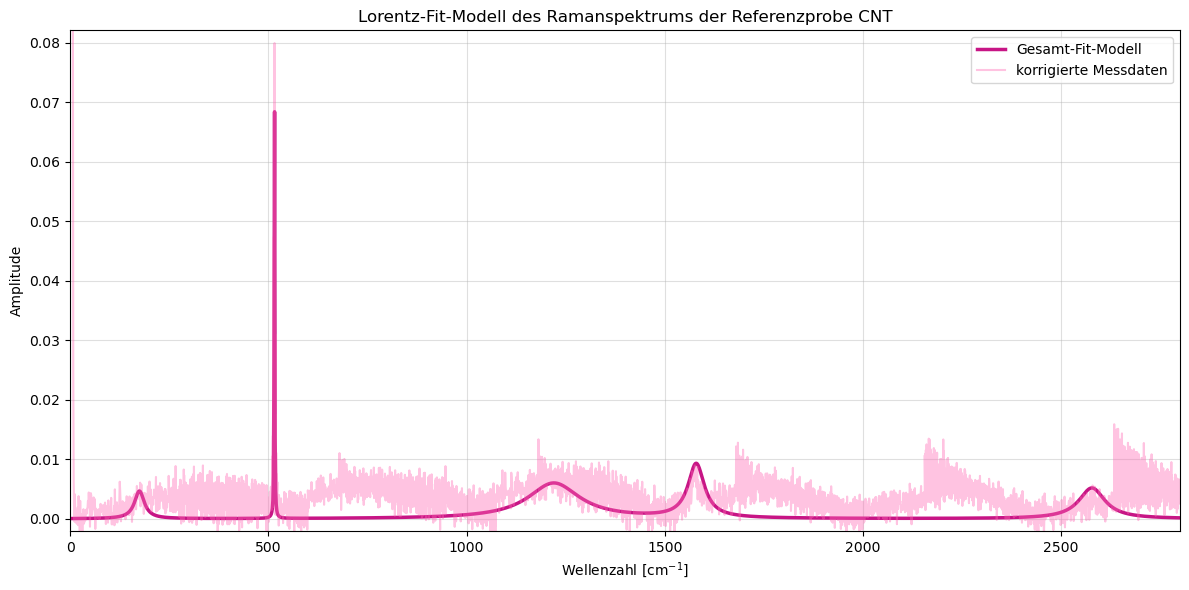

In [63]:
# kontinuierliche x-Achse für den gesamten Messbereich
x_all = np.linspace(0, 2800, 2000)

# Lorentz-Kurven
y_fit_rbm   = lorentz(x_all, *params_rbm)
y_fit_si_to = lorentz(x_all, *params_si_to)

y_fit_1200 = lorentz(x_all, *params_1200)
y_fit_g= lorentz(x_all, *params_g)

y_fit_2d    = lorentz(x_all, *params_2d)

# Gesamtspektrum = Summe aller einzelnen Fits
y_fit_gesamt = y_fit_rbm + y_fit_si_to + y_fit_1200 + y_fit_g + y_fit_2d

# Plot
plt.figure(figsize=(12, 6))
plt.xlim(0, 2800)

max_y = max(np.max(y_fit_gesamt), np.max(y_fit_2d))
plt.ylim(-0.002, max_y * 1.2)

plt.plot(x_all, y_fit_gesamt, color='mediumvioletred', linewidth=2.5, label='Gesamt-Fit-Modell')

# mathematischen Peakspitzen markieren
#plt.plot(params_rbm[1], params_rbm[0], marker='o', color='cyan', linestyle='none', label='RBM')
#plt.plot(params_si_to[1], params_si_to[0], marker='o', color='orange', linestyle='none', label='Si-TO')
#plt.plot(popt[1], popt[0], marker='o', color='red', linestyle='none', label='D-Band')
#plt.plot(popt[4], popt[3], marker='o', color='green', linestyle='none', label='G⁻-Band')
#plt.plot(popt[7], popt[6], marker='o', color='purple', linestyle='none', label='G⁺-Band')
#plt.plot(params_2d[1], params_2d[0], marker='o', color='darkorange', linestyle='none', label='2D-Band')

plt.plot(wellenzahl_cm, amplitude - baseline_full, color='hotpink', alpha=0.4, label='korrigierte Messdaten')

plt.title('Lorentz-Fit-Modell des Ramanspektrums der Referenzprobe CNT')
plt.xlabel('Wellenzahl [cm$^{-1}$]')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.4)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()